# 06 — Compare and tune models

## Goal of this step

Compare logistic regression, random forest, and XGBoost with identical training CV. Tune the best by average precision using 30 randomized settings and save its full pipeline.

## Why this matters

Model comparison is like trying three tools on the same repair jobs: changing the jobs makes the comparison unfair. Tuning adjusts a tool's settings; repeated trials can make practice scores look better than future results.

Find the project root and import display tools. Reusable logic lives in src.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np  # noqa: F401
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
plt.rcParams["figure.figsize"] = (8, 4)


Inspect candidate models and their finite search spaces. Logistic regression uses a linear boundary; random forest averages trees; XGBoost adds trees that correct previous errors.

In [2]:
from src.train import candidate_models, search_space, run_training, comparison_display, plot_fit_gap
display(pd.Series({name: repr(model) for name, model in candidate_models().items()}, name='candidates'))
display(pd.Series({name: list(search_space(name)) for name in candidate_models()}, name='searched_parameters'))

LogisticRegression    LogisticRegression(class_weight='balanced', ma...
RandomForest          RandomForestClassifier(class_weight='balanced'...
XGBoost               XGBClassifier(base_score=None, booster=None, c...
Name: candidates, dtype: str

LogisticRegression                                           [model__C]
RandomForest          [model__n_estimators, model__max_depth, model_...
XGBoost               [model__n_estimators, model__max_depth, model_...
Name: searched_parameters, dtype: object

**Interpretation:** All randomized models use seed 42 and the same preprocessing and five folds.

Select the largest mean training-CV AP, then RandomizedSearchCV tries 30 settings on that candidate. Median/scaler/encoder fitting remains inside every searched fold. The runner and notebook share an artifact fingerprint so a second execution reuses matching results.

In [3]:
comparison, metadata = run_training()
display(comparison_display(comparison))
display(pd.Series(metadata['best_params'], name='best_parameters'))
display(pd.Series({'winner': metadata['selected_model'], 'searched_settings': metadata['search_candidates'], 'tuned_CV_AP': metadata['tuned_cv_ap']}))

,roc_auc,average_precision,recall,precision,f1,accuracy
model,,,,,,
LogisticRegression,0.8465 +/- 0.0195,0.6603 +/- 0.0378,0.8034 +/- 0.0340,0.5182 +/- 0.0181,0.6300 +/- 0.0229,0.7505 +/- 0.0149
RandomForest,0.8461 +/- 0.0198,0.6598 +/- 0.0430,0.7650 +/- 0.0269,0.5395 +/- 0.0175,0.6327 +/- 0.0197,0.7651 +/- 0.0130
XGBoost,0.8478 +/- 0.0200,0.6647 +/- 0.0410,0.5178 +/- 0.0190,0.6666 +/- 0.0350,0.5827 +/- 0.0236,0.8038 +/- 0.0129
XGBoost (tuned),0.8493 +/- 0.0200,0.6646 +/- 0.0429,0.5165 +/- 0.0279,0.6747 +/- 0.0464,0.5850 +/- 0.0345,0.8061 +/- 0.0174


model__subsample             0.70
model__scale_pos_weight      1.00
model__reg_lambda            5.00
model__n_estimators        220.00
model__min_child_weight      7.00
model__max_depth             4.00
model__learning_rate         0.02
model__colsample_bytree      0.70
Name: best_parameters, dtype: float64

winner                XGBoost
searched_settings          30
tuned_CV_AP          0.664591
dtype: object

**Interpretation:** Mean +/- SD describes variation across folds, not a confidence interval. The selected CV score is optimistic because the same folds guided model and parameter choice.

Inspect train-vs-CV average precision for possible overfitting. The tuned model is refit only on all training customers; the test remains reserved.

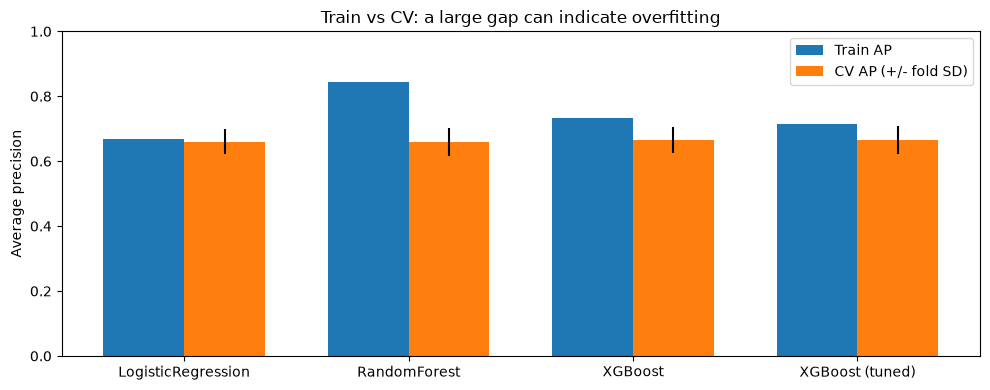

,model,train_average_precision_mean,average_precision_mean,average_precision_std
0,LogisticRegression,0.667596,0.660345,0.037833
1,RandomForest,0.845083,0.659834,0.042956
2,XGBoost,0.732063,0.664719,0.040998
3,XGBoost (tuned),0.716023,0.664591,0.042884


In [4]:
plot_fit_gap(comparison, show=True)
display(comparison[['model', 'train_average_precision_mean', 'average_precision_mean', 'average_precision_std']])

**Interpretation:** A large train/CV gap suggests memorization; weak scores on both suggest limited signal or underfitting. A complex model is not automatically better.

## Common mistakes

- Tuning using test AP.
- Assuming the selected CV score is an unbiased final estimate.
- Saving only an estimator and losing its preprocessing recipe.

## Key takeaways

- Three model families receive identical CV treatment.
- Thirty randomized candidates optimize average precision on training only.
- The saved joblib artifact includes feature creation, preprocessing, and the model.

## Next step

07_evaluation.ipynb: choose an offer threshold from training out-of-fold predictions, then open the test set once.